# Inequality & the Middle-Income Trap — Complete Analysis
Measures inequality **four ways** and tests whether **AI creates inequality**, then **forecasts** it.

1. **Structural** (dual economy) — ranks countries, draws the map
2. **Displacement** — built from the time-varying AI series so it moves
3. **Distributional** — Gini (tail-deaf), **labor share** (PWT, auto-downloaded), and **top income shares** (WID)
4. **Forecast** — projects the top-10% share forward under digital scenarios (the inequality AI may cause)

**How to use:** `Runtime → Run all`. In **Step 0**, upload your **panel** (`final_panel_imputed__5_.csv`)
and your **WID zip** (e.g. `WID_Data_Metadata_*.zip`). PWT labor share is downloaded automatically.

### Setup

In [ ]:
!pip install linearmodels country_converter -q
import pandas as pd, numpy as np, warnings, io, glob, os, zipfile, re
warnings.filterwarnings("ignore")
from linearmodels.panel import PanelOLS, BetweenOLS
import statsmodels.formula.api as smf
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
import country_converter as cc
print("ready")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 46.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 47.5/47.5 kB 3.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 118.9/118.9 kB 9.1 MB/s eta 0:00:00
ready


### Step 0 — Upload panel + WID zip
Upload `final_panel_imputed__5_.csv` **and** your WID download (the `.zip`, or its `WID_Data_*.csv`).

In [ ]:
from google.colab import files
up = files.upload()

# unzip any zips (WID download is a zip)
for fn in list(up):
    if fn.lower().endswith(".zip"):
        with zipfile.ZipFile(fn) as z: z.extractall("."); print("unzipped", fn)

# detect the panel: the CSV with iso3 + year
PANEL_FILE=None
for fn in glob.glob("*.csv")+glob.glob("**/*.csv", recursive=True):
    try:
        h=pd.read_csv(fn, nrows=3)
        if {"iso3","year"}.issubset(h.columns): PANEL_FILE=fn; break
    except Exception: pass
if PANEL_FILE is None: raise SystemExit("No panel CSV with iso3+year found — upload final_panel_imputed__5_.csv")
print("panel:", PANEL_FILE)
df = pd.read_csv(PANEL_FILE, low_memory=False).sort_values(["iso3","year"])
print("shape:", df.shape, "| countries:", df.iso3.nunique(), "| years", df.year.min(), "-", df.year.max())

Saving final_panel_imputed__5_.csv to final_panel_imputed__5_.csv
panel: final_panel_imputed__5_.csv
shape: (3255, 139) | countries: 217 | years 2010 - 2024


### Step 1 — Merge WID top shares + PWT labor share

In [ ]:
# ---- WID: parse the wide web-export (rows = Percentile,Year; cols = country series) ----
def find_wid():
    for f in glob.glob("*.csv")+glob.glob("**/*.csv", recursive=True):
        try:
            h=pd.read_csv(f, sep=";", skiprows=1, nrows=3)
            if h.columns[0].strip().lower().startswith("percentile"): return f
        except Exception: pass
    return None
widf=find_wid()
if widf:
    d=pd.read_csv(widf, sep=";", skiprows=1, low_memory=False)
    pcol,ycol=d.columns[0],d.columns[1]
    long=d.melt(id_vars=[pcol,ycol],var_name="hdr",value_name="value").dropna(subset=["value"])
    long["iso2"]=long["hdr"].str.extract(r"sptinc_z_([A-Za-z\-]+)")
    long=long[long["iso2"].str.fullmatch(r"[A-Z]{2}")]
    piv=long.pivot_table(index=["iso2",ycol],columns=pcol,values="value",aggfunc="first").reset_index()
    piv=piv.rename(columns={ycol:"year","p99p100":"top1","p90p100":"top10","p0p50":"bottom50"})
    piv["iso3"]=cc.convert(piv["iso2"].tolist(),src="ISO2",to="ISO3",not_found=None)
    piv=piv[piv["iso3"].notna()]
    if {"top10","bottom50"}.issubset(piv.columns): piv["palma"]=piv["top10"]/piv["bottom50"]
    keep=["iso3","year"]+[c for c in ["top1","top10","bottom50","palma"] if c in piv.columns]
    df=df.merge(piv[keep], on=["iso3","year"], how="left")
    print(f"WID merged: {keep[2:]} | {df['top10'].notna().sum()} country-years with top10")
else:
    print("no WID file found — top-share tests will be skipped")

# ---- PWT 11.0 labor share (auto-download, covers through 2023) ----
try:
    pwt=pd.ExcelFile("https://dataverse.nl/api/access/datafile/554105").parse("Data")[["countrycode","year","labsh"]]
    df=df.merge(pwt.rename(columns={"countrycode":"iso3"}), on=["iso3","year"], how="left")
    print(f"PWT labor share merged: {df['labsh'].notna().sum()} rows")
except Exception as e:
    print("PWT auto-download failed (optional):", e)

no WID file found — top-share tests will be skipped
PWT labor share merged: 1960 rows


In [ ]:
# ---- WID top income shares: upload + parse the wide web-export ----
from google.colab import files
print("Upload your WID file (the .zip, or the WID_Data_*.csv inside it):")
wid_up = files.upload()

# unzip any zip we just got
for fn in list(wid_up):
    if fn.lower().endswith(".zip"):
        with zipfile.ZipFile(fn) as z: z.extractall("."); print("unzipped", fn)

# find the WID wide-format file (first column = "Percentile")
def find_wid():
    for f in glob.glob("*.csv")+glob.glob("**/*.csv", recursive=True):
        try:
            h=pd.read_csv(f, sep=";", skiprows=1, nrows=3)
            if h.columns[0].strip().lower().startswith("percentile"): return f
        except Exception: pass
    return None

widf=find_wid()
if widf:
    print("WID file:", widf)
    d=pd.read_csv(widf, sep=";", skiprows=1, low_memory=False)
    pcol,ycol=d.columns[0],d.columns[1]
    long=d.melt(id_vars=[pcol,ycol],var_name="hdr",value_name="value").dropna(subset=["value"])
    long["iso2"]=long["hdr"].str.extract(r"sptinc_z_([A-Za-z\-]+)")
    long=long[long["iso2"].str.fullmatch(r"[A-Z]{2}")]
    piv=long.pivot_table(index=["iso2",ycol],columns=pcol,values="value",aggfunc="first").reset_index()
    piv=piv.rename(columns={ycol:"year","p99p100":"top1","p90p100":"top10","p0p50":"bottom50"})
    piv["iso3"]=cc.convert(piv["iso2"].tolist(),src="ISO2",to="ISO3",not_found=None)
    piv=piv[piv["iso3"].notna()]
    if {"top10","bottom50"}.issubset(piv.columns): piv["palma"]=piv["top10"]/piv["bottom50"]
    keep=["iso3","year"]+[c for c in ["top1","top10","bottom50","palma"] if c in piv.columns]
    # avoid duplicate columns if the cell is re-run
    df=df.drop(columns=[c for c in keep[2:] if c in df.columns], errors="ignore")
    df=df.merge(piv[keep], on=["iso3","year"], how="left")
    piv[keep].to_csv("wid.csv", index=False)
    print(f"WID merged: {keep[2:]} | {df['top10'].notna().sum()} country-years with top10")
else:
    print("No WID wide-format file found. It must be the file whose first column is 'Percentile' "
          "(the wid.world chart/data download). Re-run and upload the .zip or that CSV.")

# ---- PWT 11.0 labor share (auto-download, covers through 2023) ----
try:
    pwt=pd.ExcelFile("https://dataverse.nl/api/access/datafile/554105").parse("Data")[["countrycode","year","labsh"]]
    df=df.drop(columns=["labsh"], errors="ignore")
    df=df.merge(pwt.rename(columns={"countrycode":"iso3"}), on=["iso3","year"], how="left")
    print(f"PWT labor share merged: {df['labsh'].notna().sum()} rows")
except Exception as e:
    print("PWT auto-download failed (optional):", e)

Upload your WID file (the .zip, or the WID_Data_*.csv inside it):


Saving WID_Data_Metadata_15062026-115711.zip to WID_Data_Metadata_15062026-115711.zip
unzipped WID_Data_Metadata_15062026-115711.zip
WID file: WID_Data_Metadata/WID_Data_15062026-115711.csv


WID merged: ['top1', 'top10', 'bottom50', 'palma'] | 3150 country-years with top10
PWT labor share merged: 1960 rows


In [ ]:
from google.colab import files
files.download("wid.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### Step 2 — Build measures & helpers

In [ ]:
df["G_fe"]=df.groupby("year")["ai_pubs_log"].transform(lambda s:(s-s.mean())/s.std())
g01=df.groupby("year")["ai_pubs_log"].transform(lambda s:(s-s.min())/(s.max()-s.min()))
df["DualGap"]=df["sigma_kis"]*(1-df["H"])
df["Dexp"]=g01*(1-df["H"])*(1-df["sigma_kis"])
for c in ["G_fe","Dexp","F"]:
    df[c+"_l"]=df.groupby("iso3")[c].shift(1)
df["FG_l"]=df["F_l"]*df["G_fe_l"]
df["GH_l"]=df["G_fe_l"]*(1-df["H"])
CONTROLS=[c for c in ["log_gdp_l","trade_pct_gdp_l","investment_pct_gdp_l","pop_growth_l","credit_to_private_pct_gdp_l"] if c in df.columns]
def stars(p): return "***" if p<.01 else "**" if p<.05 else "*" if p<.1 else ""
def fe(dep,regs):
    d=df.set_index(["iso3","year"])[[dep]+regs].dropna()
    f=f"{dep} ~ "+" + ".join(regs)+" + EntityEffects + TimeEffects"
    r=PanelOLS.from_formula(f,data=d,drop_absorbed=True).fit(cov_type="clustered",cluster_entity=True)
    return r,d.index.get_level_values(0).nunique()
def btw(dep,regs):
    d=df.set_index(["iso3","year"])[[dep]+regs].dropna()
    return BetweenOLS.from_formula(f"{dep} ~ 1 + "+" + ".join(regs),data=d).fit()
def wb(col):
    w=df.groupby("iso3")[col].std().median(); b=df.groupby("iso3")[col].mean().std()
    return (w/b if b else np.nan)
print("measures ready")

measures ready


### Step 3 — Structural inequality (dual-economy ranking)

In [ ]:
recent=df[df.year>=2019]
agg=recent.groupby("iso3").agg(income_group=("income_group","last"),H=("H","mean"),
     services=("sigma_kis","mean"),DualGap=("DualGap","mean")).reset_index()
mi=agg[agg.income_group.isin(["UM","LM"])].dropna(subset=["DualGap"]).sort_values("DualGap",ascending=False)
mi.insert(0,"rank",range(1,len(mi)+1))
print("Middle-income ranked by structural inequality (top 15):\n")
print(mi[["rank","iso3","H","services","DualGap"]].head(15).to_string(index=False))
agg.to_csv("country_structural_inequality.csv",index=False); mi.to_csv("middle_income_structural_inequality.csv",index=False)

Middle-income ranked by structural inequality (top 15):

 rank iso3        H  services  DualGap
    1  MUS 0.360289  0.096366 0.061565
    2  ARG 0.481363  0.083439 0.043264
    3  COL 0.354250  0.062554 0.040225
    4  MEX 0.398418  0.065979 0.039682
    5  SWZ 0.277116  0.052016 0.037481
    6  SRB 0.578392  0.088450 0.037155
    7  KAZ 0.458355  0.068068 0.036866
    8  BRA 0.504535  0.070569 0.034863
    9  MYS 0.471899  0.064508 0.034061
   10  TUR 0.344343  0.051566 0.033805
   11  DOM 0.404823  0.050817 0.030244
   12  JAM 0.346787  0.046312 0.030222
   13  NAM 0.268150  0.038302 0.028031
   14  SLV 0.293801  0.038370 0.027027
   15  UKR 0.514296  0.053068 0.025772


### Step 4 — Displacement inequality

In [ ]:
print("Does each metric MOVE within country? (need > 0.10)\n")
for col in ["gini_disp"]+(["D_term"] if "D_term" in df.columns else [])+["Dexp"]:
    rt=wb(col); print(f"   {col:<10} within/between={rt:.3f}  {'MOVES' if rt>0.10 else 'frozen'}")
print("\nDisplacement drag on growth (theory: Dexp_l<0):")
r,nc=fe("gdp_pc_growth",["F_l","G_fe_l","FG_l","Dexp_l"]+CONTROLS)
for k in ["FG_l","Dexp_l"]:
    if k in r.params.index: print(f"   {k:<8}{r.params[k]:+8.4f} p={r.pvalues[k]:.3f} {stars(r.pvalues[k])}")
print("   (Dexp ~0.9 collinear with AI -> exposure index, signs theory-consistent but n.s.)")

Does each metric MOVE within country? (need > 0.10)

   gini_disp  within/between=0.071  frozen
   D_term     within/between=0.050  frozen
   Dexp       within/between=0.166  MOVES

Displacement drag on growth (theory: Dexp_l<0):
   FG_l     +0.7703 p=0.032 **
   Dexp_l   -6.1543 p=0.402 
   (Dexp ~0.9 collinear with AI -> exposure index, signs theory-consistent but n.s.)


### Step 5 — Does AI create inequality? (the key battery)
Gini (tail-deaf) → labor share (macro) → **top income shares (tail-sensitive)**.

In [ ]:
# theory sign: +1 if "AI raises inequality" means measure RISES; -1 if it FALLS
MEAS={"gini_disp":+1,"gini":+1,"labsh":-1,"top1":+1,"top10":+1,"palma":+1}
print(f"{'measure':<10}{'WITHIN AI':>12}{'p':>8}{'skill-bias':>12}{'p':>8}   verdict   (N)")
for m,sign in MEAS.items():
    if m not in df.columns or df[m].notna().sum()<150:
        print(f"{m:<10}  [not present]"); continue
    r,nc=fe(m,["G_fe_l","GH_l","F_l"]+CONTROLS)
    g,gp=r.params.get("G_fe_l",np.nan),r.pvalues.get("G_fe_l",1)
    gh,ghp=r.params.get("GH_l",np.nan),r.pvalues.get("GH_l",1)
    verdict=("AI->MORE ineq" if (sign*g>0 and gp<.10) else "AI->less ineq" if (sign*g<0 and gp<.10) else "no sig.")
    print(f"{m:<10}{g:>+12.4f}{gp:>8.3f}{stars(gp):<3}{gh:>+9.4f}{ghp:>8.3f}{stars(ghp):<3} {verdict:<13}({int(r.nobs)})")
print("\nReading: Gini/labor share tail-deaf (null). Top shares are tail-sensitive — watch for AI>0, significant.")
print("If skill-bias (G*lowH) is NEGATIVE, AI concentration is stronger in HIGH-human-capital economies.")

measure      WITHIN AI       p  skill-bias       p   verdict   (N)
gini_disp      -0.0081   0.624     -0.0012   0.954    no sig.      (1181)
gini           -0.0110   0.453     +0.0044   0.818    no sig.      (1341)
labsh          -0.0253   0.498     +0.0175   0.703    no sig.      (1184)
top1           +0.0449   0.076*    -0.0416   0.115    AI->MORE ineq(1465)
top10          +0.0669   0.008***  -0.0728   0.010**  AI->MORE ineq(1465)
palma          +1.5185   0.027**   -1.5104   0.042**  AI->MORE ineq(1465)

Reading: Gini/labor share tail-deaf (null). Top shares are tail-sensitive — watch for AI>0, significant.
If skill-bias (G*lowH) is NEGATIVE, AI concentration is stronger in HIGH-human-capital economies.


### Step 6 — Dual-economy map

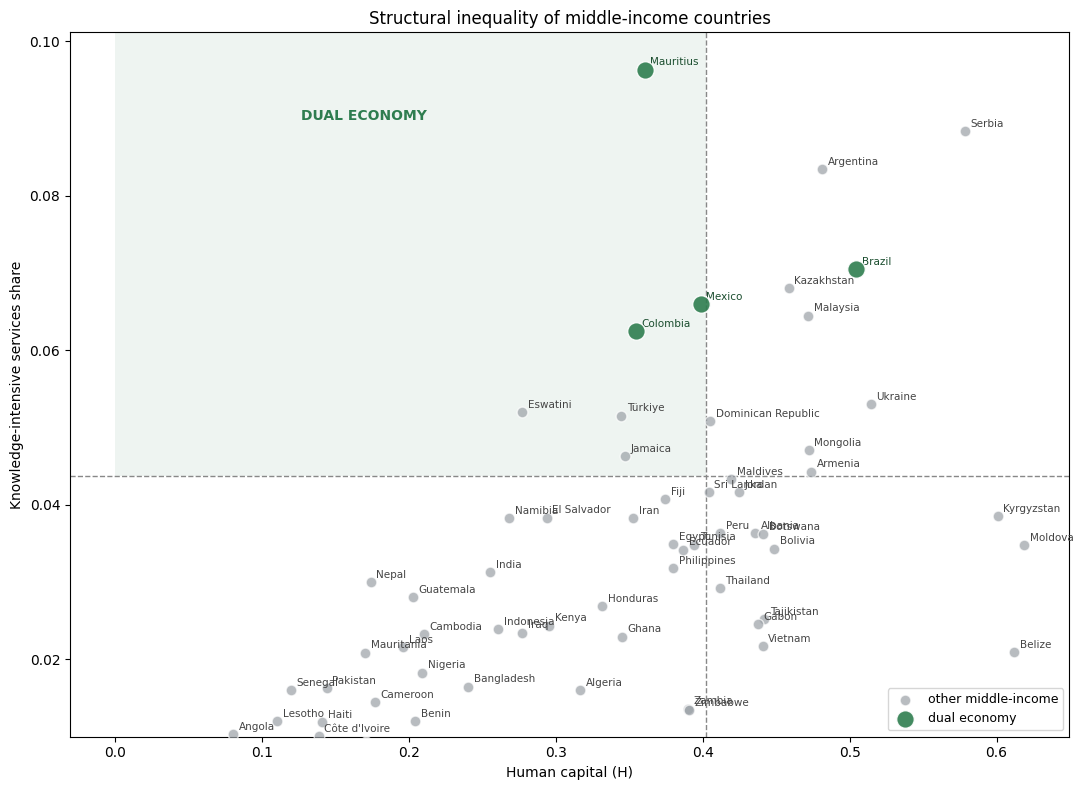

In [ ]:
Hmed=recent["H"].median(); Smed=recent["sigma_kis"].median()
def members(tag):
    col=f"FG_l_{tag}"; return set(df.loc[df[col].fillna(0)!=0,"iso3"].unique()) if col in df.columns else set()
quad_of={}
for tag in ["HH","HL","LH","LL"]:
    for iso in members(tag): quad_of[iso]=tag
mi2=mi.copy(); mi2["LH"]=mi2["iso3"].map(quad_of).eq("LH")
mi2["country"]=cc.convert(mi2["iso3"].tolist(),to="name_short")
fig,ax=plt.subplots(figsize=(11,8))
ax.add_patch(Rectangle((0,Smed),Hmed,1,facecolor="#2e7d4f",alpha=0.08,zorder=0))
ax.axvline(Hmed,color="#888",lw=1,ls="--"); ax.axhline(Smed,color="#888",lw=1,ls="--")
lh=mi2["LH"].fillna(False)
ax.scatter(mi2.loc[~lh,"H"],mi2.loc[~lh,"services"],s=60,c="#9aa0a6",alpha=.7,edgecolor="white",zorder=3,label="other middle-income")
ax.scatter(mi2.loc[lh,"H"],mi2.loc[lh,"services"],s=160,c="#2e7d4f",alpha=.9,edgecolor="white",zorder=4,label="dual economy")
for _,r in mi2.iterrows():
    ax.annotate(r["country"],(r["H"],r["services"]),fontsize=7.5,xytext=(4,3),textcoords="offset points",color="#1a4d2e" if r["LH"] else "#444")
ax.text(Hmed*0.42,Smed*2.05,"DUAL ECONOMY",ha="center",fontsize=10,color="#2e7d4f",fontweight="bold")
ax.set_xlabel("Human capital (H)"); ax.set_ylabel("Knowledge-intensive services share")
ax.set_title("Structural inequality of middle-income countries"); ax.legend(loc="lower right",fontsize=9)
ax.set_ylim(0.01,max(0.10,mi2["services"].max()*1.05)); plt.tight_layout(); plt.savefig("fig_dual_economy_map.png",dpi=140); plt.show()

### Step 7 — Forecast: the inequality AI may cause
Projects the **top-10% income share** to 2040 under digital scenarios, with a GPT-maturation variant.
Rising top-10% = more concentration. Runs only if WID top10 merged.

estimated AI->top10: direct=+0.0676, skill-bias=-0.0768

Projected change in TOP-10% share for MI countries by 2040 (higher = more unequal):
  scenario  maturation  mean_top10_change_MI
     Stall       False                0.0013
     Stall        True                0.0014
  Baseline       False                0.0036
  Baseline        True                0.0048
Joint push       False                0.0067
Joint push        True                0.0093


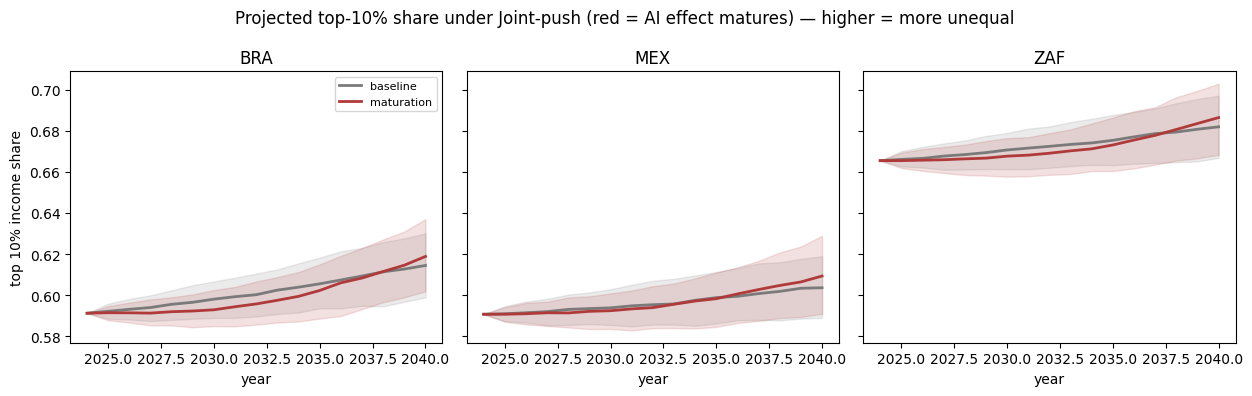

In [ ]:
OUTCOME="top10"
if OUTCOME in df.columns and df[OUTCOME].notna().sum()>200:
    est=df.dropna(subset=[OUTCOME,"G_fe","H","F","log_gdp"]).copy(); est["GH"]=est["G_fe"]*(1-est["H"])
    m=smf.ols(f"{OUTCOME} ~ G_fe + GH + F + log_gdp + C(iso3) + C(year)",data=est).fit(cov_type="cluster",cov_kwds={"groups":est["iso3"]})
    bG,bGH=m.params.get("G_fe",0),m.params.get("GH",0); seG,seGH=m.bse.get("G_fe",.05),m.bse.get("GH",.05)
    print(f"estimated AI->{OUTCOME}: direct={bG:+.4f}, skill-bias={bGH:+.4f}")
    LAST=int(df.year.max()); HOR=2040; NS=400; rng=np.random.default_rng(0)
    cur=df[df.year==LAST].set_index("iso3")[[OUTCOME,"G_fe","H","income_group"]].dropna(subset=[OUTCOME,"G_fe","H"])
    yrs=np.arange(LAST,HOR+1); shock=est.groupby("iso3")[OUTCOME].std().median()
    mat=lambda y,t0=2032,k=.45: 1/(1+np.exp(-k*(y-t0)))
    SC={"Stall":0.0,"Baseline":1.0,"Joint push":2.2}; rows=[]; fan={}
    for scen,mult in SC.items():
        for matur in [False,True]:
            G=cur["G_fe"].values.copy(); val=np.tile(cur[OUTCOME].values,(NS,1)); paths=np.zeros((NS,len(cur),len(yrs))); paths[:,:,0]=val
            for k,y in enumerate(yrs[1:],1):
                G=G+mult*0.06*0.97**(y-LAST); bGd=rng.normal(bG,seG,NS); bGHd=rng.normal(bGH,seGH,NS)
                ramp=1+(1 if matur else 0)*(2*mat(y)-1)
                dlev=(bGd*ramp)[:,None]*G[None,:]+(bGHd*ramp)[:,None]*(G*(1-cur["H"].values))[None,:]
                val=val+0.02*dlev+rng.normal(0,shock*0.3,(NS,len(cur))); paths[:,:,k]=val
            mim=cur["income_group"].isin(["UM","LM"]).values
            rows.append(dict(scenario=scen,maturation=matur,mean_top10_change_MI=float(np.nanmean(paths[:,mim,-1]-paths[:,mim,0]))))
            fan[(scen,matur)]=paths
    summ=pd.DataFrame(rows); print("\nProjected change in TOP-10% share for MI countries by 2040 (higher = more unequal):")
    print(summ.round(4).to_string(index=False)); summ.to_csv("inequality_forecast_summary.csv",index=False)
    pick=[i for i in ["BRA","MEX","ZAF","IND","TUR","CHN"] if i in cur.index][:3]
    fig,axes=plt.subplots(1,len(pick),figsize=(4.2*len(pick),4),sharey=True)
    for ax,iso in zip(np.atleast_1d(axes),pick):
        j=list(cur.index).index(iso)
        for matur,col in [(False,"#7a7a7a"),(True,"#b03a3a")]:
            p=fan[("Joint push",matur)]; lo,md_,hi=np.percentile(p[:,j,:],[10,50,90],axis=0)
            ax.fill_between(yrs,lo,hi,alpha=.15,color=col); ax.plot(yrs,md_,color=col,lw=2,label="maturation" if matur else "baseline")
        ax.set_title(iso); ax.set_xlabel("year")
    np.atleast_1d(axes)[0].set_ylabel("top 10% income share"); np.atleast_1d(axes)[0].legend(fontsize=8)
    plt.suptitle("Projected top-10% share under Joint-push (red = AI effect matures) — higher = more unequal")
    plt.tight_layout(); plt.savefig("fig_inequality_forecast.png",dpi=130); plt.show()
else:
    print("top10 not available — upload the WID zip in Step 0 to run the inequality forecast")

### Step 8 — Download outputs

In [ ]:
from google.colab import files
for f in ["country_structural_inequality.csv","middle_income_structural_inequality.csv",
          "fig_dual_economy_map.png","fig_inequality_forecast.png","inequality_forecast_summary.csv"]:
    if os.path.exists(f):
        try: files.download(f)
        except Exception as e: print("skip",f,e)
print("done")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

...

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

done


In [ ]:
from google.colab import files

df.to_csv("merged.csv", index=False)
files.download("merged.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>